# Датасет мест Нижнего Новгорода для разговорных рекомендаций

Постановка задания номер 1: **Нижний Новгород, радиус 5 км от Кремля, 100 мест и шесть категорий**. Это не весь город, а выборка вокруг центра; если позже понадобится геопоиск по всему городу, географию можно расширить отдельно

## 0. Подготовка окружения

In [1]:
%pip install -q pandas requests osmnx geopandas numpy matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import difflib
import html
import json
import math
import re
import time
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import osmnx as ox
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

CITY = "Нижний Новгород"
CENTER_POINT = (56.3290, 44.0020)  # Нижегородский кремль
DIST = 5_000                    # радиус поиска, метры
RANDOM_STATE = 42
TARGET_SIZE = 100

QUOTAS = {
    "Кафе": 20,
    "Рестораны": 20,
    "Бары и пабы": 10,
    "Музеи": 15,
    "Достопримечательности и исторические места": 20,
    "Парки и сады": 15,
}
assert sum(QUOTAS.values()) == TARGET_SIZE

TAGS = {
    "amenity": ["cafe", "restaurant", "bar", "pub"],
    "tourism": ["museum", "attraction"],
    "leisure": ["park", "garden"],
    "historic": True,
}

# использую то зеркало Overpass, с которым мне было проще работать, тестились и другие варианты
ox.settings.overpass_url = "https://maps.mail.ru/osm/tools/overpass/api"
ox.settings.overpass_rate_limit = True
ox.settings.requests_timeout = 180
ox.settings.use_cache = True

# кэш, чтоб второй раз не ждать
CACHE_DIR = Path.cwd() / ".poi_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Кэш внешних источников:", CACHE_DIR.resolve())

session = requests.Session()
session.headers.update({
    "User-Agent": "HSE-POI-research/1.0 (educational project; contact: notebook owner)"
})

print("OSMnx:", ox.__version__)
print("Город:", CITY, "| радиус:", DIST, "м | цель:", TARGET_SIZE, "мест")

Кэш внешних источников: C:\Users\HONOR\projects_hse\conversational_reccs\.poi_cache
OSMnx: 2.1.1
Город: Нижний Новгород | радиус: 5000 м | цель: 100 мест


## Задание 1. Сбор датасета

### 1.1. Источник, география и категории

Сначала я использую OpenStreetMap: его достаточно, чтобы собрать нужное количество объектов и получить базовые поля — название, категорию, координаты, адрес, часы работы и некоторые теги. Но у osm хватает своих минусов, например, практически нет описаний, абсолютно нет отзывов (об этом еще будет обговорено) и в целом многие теги пропускаются, поэтому датасет надо будет обогощать 

Я не пытаюсь сразу собрать идеальную базу. Для начала нужны 100 разных мест с понятными категориями. Поэтому фиксирую квоты: так в выборке не будет одних кафе, даже если OSM хранит их намного больше, чем музеев или парков

| Категория | Количество |
|---|---:|
| Кафе | 20 |
| Рестораны | 20 |
| Бары и пабы | 10 |
| Музеи | 15 |
| Достопримечательности и исторические места | 20 |
| Парки и сады | 15 |

Объекты OSM могут быть точками, линиями или полигонами. Для линий и площадей беру representative point - это удобная координата для поиска, однако у этого есть свои минусы (например, если парк большой, а вход только с одного края, пользователь вполне может опираться на координату не входа, а просто какую-то точку внутри). Но все же, для этого задания считаю некритичным

In [3]:
print("Загружаю объекты OpenStreetMap...")
gdf = ox.features_from_point(CENTER_POINT, TAGS, dist=DIST)
print("Всего объектов загружено:", len(gdf))

gdf = gdf[gdf["name"].notna()].copy()
print("Объектов с названием:", len(gdf))

Загружаю объекты OpenStreetMap...
Всего объектов загружено: 1527
Объектов с названием: 1161


In [4]:
# категоризация

def classify(row):
    amenity = row.get("amenity")
    tourism = row.get("tourism")
    leisure = row.get("leisure")
    historic = row.get("historic")

    if amenity == "cafe":
        return "Кафе"
    if amenity == "restaurant":
        return "Рестораны"
    if amenity in ["bar", "pub"]:
        return "Бары и пабы"
    if tourism == "museum":
        return "Музеи"
    if tourism == "attraction" or pd.notna(historic):
        return "Достопримечательности и исторические места"
    if leisure in ["park", "garden"]:
        return "Парки и сады"
    return None


def valid_name(name): # при первых попытках работы с данными были названия по типу "A", "H", и какие-то будто коды "A22BB"
                      # поэтому нужна валидация таких названий, т. к. датасет небольшой, в целом даже глазами видно, что фильтр помог
    name = str(name).strip()
    if len(name) < 2:
        return False
    letters = re.findall(r"[^\W\d_]", name, flags=re.UNICODE)
    return len(letters) >= 2


def normalize_name(name):
    name = unicodedata.normalize("NFKC", str(name)).casefold()
    return re.sub(r"\s+", " ", name).strip()


gdf["category"] = gdf.apply(classify, axis=1)
gdf = gdf[gdf["category"].notna() & gdf["name"].apply(valid_name)].copy()
gdf["osm_type"] = gdf.index.get_level_values(0).astype(str)
gdf["osm_id"] = gdf.index.get_level_values(1).astype(str)
gdf["place_id"] = gdf["osm_type"] + "_" + gdf["osm_id"]

gdf = gdf.to_crs("EPSG:4326")
representative_points = gdf.geometry.representative_point() # для линий и областей тоже возьмет одну точку
gdf["lat"] = representative_points.y
gdf["lon"] = representative_points.x

gdf["normalized_name"] = gdf["name"].map(normalize_name)
gdf["lat_key"] = gdf["lat"].round(6)
gdf["lon_key"] = gdf["lon"].round(6)
before = len(gdf)
gdf = gdf.drop_duplicates(subset=["normalized_name", "lat_key", "lon_key"]).copy()
print("После очистки и удаления полных дублей:", len(gdf), "| удалено:", before - len(gdf))

После очистки и удаления полных дублей: 1146 | удалено: 0


Дубли удаляю только при совпадении нормализованного названия и почти точных координат. Одно название само по себе не считаю дублем: в городе могут быть разные места с одинаковыми именами, ну или одно и то же место, но в разных точках (если бы учитывали местоположение пользователя, можно было бы предлагать ближайшие места, эти данные бы помогли). Округление координат до 6 знаков здесь используется как технический ключ для удаления практически совпадающих точек

In [5]:
# кандидаты

def scalar_or_none(value):
    if value is None:
        return None
    try:
        missing = pd.isna(value)
        if isinstance(missing, (bool, np.bool_)) and missing:
            return None
    except (TypeError, ValueError):
        pass
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, (str, int, float, bool)):
        return value
    return str(value)


def get_value(row, key):
    value = row.get(key)
    value = scalar_or_none(value)
    if value is None or str(value).strip() == "":
        return None
    return value


def get_address(row):
    city = get_value(row, "addr:city") or CITY
    street = get_value(row, "addr:street")
    house = get_value(row, "addr:housenumber")
    if street and house:
        return f"{city}, {street}, {house}"
    if street:
        return f"{city}, {street}"
    return city


def tags_to_json(row):
    tags = {}
    for key, value in row.items():
        if key == "geometry" or key in {"lat", "lon", "normalized_name", "lat_key", "lon_key"}:
            continue
        value = scalar_or_none(value)
        if value is not None:
            tags[str(key)] = value
    return json.dumps(tags, ensure_ascii=False)


def column_values(frame, column):
    if column in frame.columns:
        return frame[column].map(scalar_or_none).values
    return [None] * len(frame)

candidates = pd.DataFrame({

    # до такого набора полей пришел со временем, спустя различные варианты поиска данных
    # например, чтобы заполнить поля описаний пригодится wikidata/wikipedia, какими-то полями вдохновился из overture
    # оставил наиболее нужные

    "place_id": gdf["place_id"].values,
    "name": gdf["name"].astype(str).str.strip().values,
    "category": gdf["category"].values,
    "osm_type": gdf["osm_type"].values,
    "osm_id": gdf["osm_id"].values,
    "lat": gdf["lat"].values,
    "lon": gdf["lon"].values,
    "address": gdf.apply(get_address, axis=1).values,
    "district": gdf.apply(lambda row: get_value(row, "addr:district") or get_value(row, "addr:suburb") or get_value(row, "addr:city_district"), axis=1).values,
    "description_osm": column_values(gdf, "description"),
    "website": column_values(gdf, "website"),
    "phone": column_values(gdf, "phone"),
    "opening_hours": column_values(gdf, "opening_hours"),
    "cuisine": column_values(gdf, "cuisine"),
    "wikidata": column_values(gdf, "wikidata"),
    "wikipedia_tag": column_values(gdf, "wikipedia"),
    "outdoor_seating": column_values(gdf, "outdoor_seating"),
    "internet_access": column_values(gdf, "internet_access"),
    "wheelchair": column_values(gdf, "wheelchair"),
    "tags_json": gdf.apply(tags_to_json, axis=1).values,
    "source": ["OpenStreetMap"] * len(gdf),
})

print("Кандидатов после очистки:", len(candidates))
display(candidates.head(5))

Кандидатов после очистки: 1146


,place_id,name,category,osm_type,osm_id,lat,lon,address,district,description_osm,website,phone,opening_hours,cuisine,wikidata,wikipedia_tag,outdoor_seating,internet_access,wheelchair,tags_json,source
0,node_262652256,М. Горькому,Достопримечательности и исторические места,node,262652256,56.313480,43.990713,Нижний Новгород,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""historic"": ""memorial"", ""memorial"": ""statue"", ""memorial:subject"": ""Максим Горький"", ""name"": ""М....",OpenStreetMap
1,node_262652496,Козьме Минину,Достопримечательности и исторические места,node,262652496,56.326768,44.006882,Нижний Новгород,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""historic"": ""memorial"", ""memorial"": ""statue"", ""name"": ""Козьме Минину"", ""material"": ""metal"", ""ca...",OpenStreetMap
2,node_262652551,В. П. Чкалову,Достопримечательности и исторические места,node,262652551,56.330030,44.009419,Нижний Новгород,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""historic"": ""memorial"", ""memorial"": ""statue"", ""memorial:subject"": ""Валерий Павлович Чкалов"", ""n...",OpenStreetMap
3,node_479501527,Максиму Горькому,Достопримечательности и исторические места,node,479501527,56.324460,43.983497,Нижний Новгород,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""historic"": ""memorial"", ""memorial"": ""statue"", ""name"": ""Максиму Горькому"", ""category"": ""Достопри...",OpenStreetMap
4,node_597408721,Лопасть рабочего колеса гидравлической турбины Горьковской ГЭС,Достопримечательности и исторические места,node,597408721,56.318685,43.987136,Нижний Новгород,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""historic"": ""technical_monument"", ""name"": ""Лопасть рабочего колеса гидравлической турбины Горьк...",OpenStreetMap


### 1.5. Отбор 100 мест

Вариант из первого черновика — случайная выборка внутри каждой категории. Из ZIP-проекта я беру более полезную идею: сначала выбираю часть объектов с более заполненными карточками, а остаток добираю случайно. Так у нас будет больше данных для обогащения, но итоговая выборка не превратится только в список известных мест.

Скоринг — техническая эвристика, а не оценка качества места: Wikidata/Wikipedia, сайт, телефон, часы, кухня и описание дают баллы. Внутри каждой квоты около 65% беру из карточек с высоким скорингом, оставшиеся 35% — случайно с фиксированным seed. Если в какой-то категории объектов не хватит, код покажет недобор, а не будет молча менять квоты.

In [6]:
# отбор по квотам - полнота карточки + случайная часть

def completeness(row):
    score = 0
    score += 3 * bool(row.get("wikidata"))
    score += 2 * bool(row.get("wikipedia_tag"))
    score += 2 * bool(row.get("website"))
    score += 1 * bool(row.get("phone"))
    score += 1 * bool(row.get("opening_hours"))
    score += 1 * bool(row.get("cuisine"))
    score += 1 * bool(row.get("description_osm"))
    return score

candidates["completeness_score"] = candidates.apply(completeness, axis=1)
selected_parts = []
selection_report = []

for category, target in QUOTAS.items():
    subset = candidates[candidates["category"] == category].copy()
    if subset.empty:
        selection_report.append({"category": category, "quota": target, "available": 0, "selected": 0})
        continue

    n_top = min(len(subset), int(round(target * 0.65)))
    top = subset.sort_values(
        ["completeness_score", "name"], ascending=[False, True]
    ).head(n_top)
    remainder = subset[~subset["place_id"].isin(top["place_id"])]
    n_random = min(max(0, target - len(top)), len(remainder))
    random_part = remainder.sample(n=n_random, random_state=RANDOM_STATE) if n_random else remainder.head(0)
    chosen = pd.concat([top, random_part], ignore_index=False).drop_duplicates("place_id")
    selected_parts.append(chosen)
    selection_report.append({
        "category": category, "quota": target,
        "available": len(subset), "selected": len(chosen)
    })

selection_report = pd.DataFrame(selection_report)
df_places = pd.concat(selected_parts, ignore_index=True) if selected_parts else pd.DataFrame()
df_places = df_places.drop_duplicates("place_id").reset_index(drop=True)

print("Распределение после отбора:")
display(selection_report)
print("Итого выбрано мест:", len(df_places))
print(df_places["category"].value_counts().reindex(QUOTAS.keys(), fill_value=0))
if len(df_places) != TARGET_SIZE:
    print("ВНИМАНИЕ: квоты закрыты не полностью. Проверь таблицу доступных кандидатов выше.")

# первый датасет пока с малым нбором данных, но уже с сотней мест
df_places.to_csv("places_raw.csv", index=False, encoding="utf-8-sig")
print("Сохранён файл places_raw.csv")
display(df_places[["name", "category", "address", "completeness_score"]].head(10))

Распределение после отбора:


,category,quota,available,selected
0,Кафе,20,333,20
1,Рестораны,20,148,20
2,Бары и пабы,10,81,10
3,Музеи,15,45,15
4,Достопримечательности и исторические места,20,498,20
5,Парки и сады,15,41,15


Итого выбрано мест: 100
category
Кафе                                          20
Рестораны                                     20
Бары и пабы                                   10
Музеи                                         15
Достопримечательности и исторические места    20
Парки и сады                                  15
Name: count, dtype: int64
Сохранён файл places_raw.csv


,name,category,address,completeness_score
0,#Бургер,Кафе,"Нижний Новгород, улица Фильченкова Героя, 10",11
1,5 минут,Кафе,Нижний Новгород,11
2,7 гость,Кафе,Нижний Новгород,11
3,Aloha & poke vibe,Кафе,Нижний Новгород,11
4,Alt lib,Кафе,Нижний Новгород,11
5,Artcoffee,Кафе,Нижний Новгород,11
6,Aura-кальянная,Кафе,Нижний Новгород,11
7,Beerлога,Кафе,Нижний Новгород,11
8,Biblioteca,Кафе,Нижний Новгород,11
9,Black Bat Cafe,Кафе,"Нижний Новгород, улица Бекетова, 8",11


### 1.7. Обогащение через Wikipedia и Wikidata

У исходного OSM-датасета не хватает описаний. Сначала использую ссылки `wikidata` и `wikipedia`, если они уже проставлены в тегах. Для Wikidata получаю название русской статьи и количество языковых версий - последнее использую только как скорее не как оценку качества, а просто подтверждение хоть какой-то популярности

Для оставшихся музеев, достопримечательностей и парков есть запасной поиск статьи по названию. Но принимаю результат только если у статьи есть координаты, она находится не дальше 1,2 км от точки места и название достаточно похоже. Просто совпадения по названию недостаточно: иначе можно приписать небольшому заведению статью о другом объекте, уж лучше пустое поле чем так

API-ответы тоже кэшируются в `.poi_cache`

In [7]:
# реализация полезных функций

def api_get(url, params=None, retries=4, timeout=45):
    last_error = None
    for attempt in range(retries):
        try:
            response = session.get(url, params=params or {}, timeout=timeout)
            if response.status_code in (429, 500, 502, 503, 504):
                time.sleep(2 * (attempt + 1))
                continue
            response.raise_for_status()
            return response.json()
        except requests.RequestException as exc:
            last_error = exc
            time.sleep(1.5 * (attempt + 1))
    raise RuntimeError(f"Не удалось выполнить запрос к {url}: {last_error}") 


def clean_text(value, limit=None):
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return ""
    text = html.unescape(str(value))
    text = re.sub(r"\s+", " ", text).strip()
    if limit and len(text) > limit:
        text = text[:limit].rsplit(" ", 1)[0].rstrip()
    return text


def chunks(values, size):
    values = list(values)
    for start in range(0, len(values), size):
        yield values[start:start + size]


def normalize_for_match(value):
    value = unicodedata.normalize("NFKC", str(value or "")).casefold().replace("ё", "е")
    value = re.sub(r"[«»\"'`]+", "", value)
    value = re.sub(r"\b(им\.|имени)\b", " ", value)
    value = re.sub(r"[^а-яa-z0-9 ]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()

In [8]:
# Wikipedia
WIKIPEDIA_API = "https://ru.wikipedia.org/w/api.php"
WIKIDATA_API = "https://www.wikidata.org/w/api.php"
wiki_cache_path = CACHE_DIR / "wiki_enrichment.json"
if wiki_cache_path.exists():
    wiki_info = json.loads(wiki_cache_path.read_text(encoding="utf-8"))
else:
    wiki_info = {}


def wikidata_links(qids):
    result = {}
    qids = sorted({str(q).strip() for q in qids if pd.notna(q) and re.fullmatch(r"Q\d+", str(q).strip())})
    for part in chunks(qids, 50):
        data = api_get(WIKIDATA_API, {
            "action": "wbgetentities", "ids": "|".join(part),
            "props": "sitelinks", "format": "json"
        })
        for qid, entity in data.get("entities", {}).items():
            links = entity.get("sitelinks", {})
            result[qid] = {
                "title": (links.get("ruwiki") or {}).get("title", ""),
                "n_links": len(links),
            }
    return result


def wikipedia_extracts(titles):
    result = {}
    titles = sorted({t for t in titles if t})
    for part in chunks(titles, 20):
        data = api_get(WIKIPEDIA_API, {
            "action": "query", "prop": "extracts", "exintro": 1,
            "explaintext": 1, "titles": "|".join(part),
            "format": "json", "formatversion": 2, "redirects": 1
        })
        for page in data.get("query", {}).get("pages", []):
            if page.get("extract"):
                result[page["title"]] = clean_text(page["extract"], 1200)
    return result


# запрашиваю только те места, которых ещё нет в кэше
new_places = df_places[~df_places["place_id"].astype(str).isin(wiki_info)].copy()
qids = new_places["wikidata"].dropna().astype(str).unique().tolist()
wd_info = wikidata_links(qids) if qids else {}

title_by_place = {}
for _, row in new_places.iterrows():
    qid = clean_text(row.get("wikidata"))
    title = wd_info.get(qid, {}).get("title", "")
    if not title:
        raw_wikipedia = clean_text(row.get("wikipedia_tag"))
        if ":" in raw_wikipedia:
            lang, possible_title = raw_wikipedia.split(":", 1)
            if lang.casefold() == "ru":
                title = possible_title.strip()
        elif raw_wikipedia:
            title = raw_wikipedia
    title_by_place[row["place_id"]] = title

extract_by_title = wikipedia_extracts(title_by_place.values())
for _, row in new_places.iterrows():
    qid = clean_text(row.get("wikidata"))
    title = title_by_place.get(row["place_id"], "")
    wiki_info[str(row["place_id"])] = {
        "title": title,
        "extract": extract_by_title.get(title, ""),
        "n_links": wd_info.get(qid, {}).get("n_links", 0),
        "via": "wikidata" if title and wd_info.get(qid, {}).get("title") == title else ("osm_wikipedia_tag" if title else "")
    }

wiki_cache_path.write_text(json.dumps(wiki_info, ensure_ascii=False, indent=2), encoding="utf-8")

df_places["wiki_title"] = df_places["place_id"].astype(str).map(lambda pid: wiki_info.get(pid, {}).get("title", ""))
df_places["wiki_extract"] = df_places["place_id"].astype(str).map(lambda pid: wiki_info.get(pid, {}).get("extract", ""))
df_places["n_wiki_links"] = df_places["place_id"].astype(str).map(lambda pid: wiki_info.get(pid, {}).get("n_links", 0))
print("Мест с описанием из Wikipedia на этом шаге:", int(df_places["wiki_extract"].fillna("").ne("").sum()))

Мест с описанием из Wikipedia на этом шаге: 13


Для мест без описания пробую поиск по названию только в культурных категориях. Это необязательный fallback, поэтому он проверяется отдельно; если статьи не нашлось или координаты не подходят, поле остаётся пустым

In [9]:
# запасной поиск вики

def haversine_m(lat1, lon1, lat2, lon2):
    earth_radius = 6_371_000
    lat1, lon1, lat2, lon2 = map(math.radians, [float(lat1), float(lon1), float(lat2), float(lon2)])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    return 2 * earth_radius * math.asin(math.sqrt(a))

CULTURAL_CATEGORIES = {
    "Музеи", "Достопримечательности и исторические места", "Парки и сады"
}
added_by_search = 0
wiki_search_errors = 0

for idx, row in df_places.iterrows():
    pid = str(row["place_id"])
    if clean_text(row.get("wiki_extract")) or row["category"] not in CULTURAL_CATEGORIES:
        continue

    # проверенное не проверяю повторно
    if wiki_info.get(pid, {}).get("via") == "search_checked":
        continue
    try:
        data = api_get(WIKIPEDIA_API, {
            "action": "query", "generator": "search",
            "gsrsearch": f'{row["name"]} {CITY}', "gsrlimit": 3,
            "prop": "coordinates|extracts", "exintro": 1, "explaintext": 1,
            "format": "json", "formatversion": 2, "colimit": "max"
        })
        accepted = None
        for page in data.get("query", {}).get("pages", []):
            coords = (page.get("coordinates") or [{}])[0]
            extract = clean_text(page.get("extract"))
            if not coords or not extract:
                continue
            distance = haversine_m(row["lat"], row["lon"], coords["lat"], coords["lon"])
            similarity = difflib.SequenceMatcher(
                None, normalize_for_match(row["name"]), normalize_for_match(page["title"])
            ).ratio()
            if distance <= 1200 and similarity >= 0.55:
                accepted = {
                    "title": page["title"], "extract": clean_text(extract, 1200),
                    "n_links": 0, "via": "wikipedia_search"
                }
                break
        if accepted:
            wiki_info[pid] = accepted
            added_by_search += 1
        else:
            wiki_info[pid] = {**wiki_info.get(pid, {}), "via": "search_checked"}
    except Exception as exc:
        wiki_search_errors += 1
        print(f'Поиск для «{row["name"]}» не удался: {exc}')
    time.sleep(0.15)

wiki_cache_path.write_text(json.dumps(wiki_info, ensure_ascii=False, indent=2), encoding="utf-8")
df_places["wiki_title"] = df_places["place_id"].astype(str).map(lambda pid: wiki_info.get(pid, {}).get("title", ""))
df_places["wiki_extract"] = df_places["place_id"].astype(str).map(lambda pid: wiki_info.get(pid, {}).get("extract", ""))
df_places["n_wiki_links"] = df_places["place_id"].astype(str).map(lambda pid: wiki_info.get(pid, {}).get("n_links", 0))
print("Дополнительно найдено статей:", added_by_search, "| ошибок запросов:", wiki_search_errors)
print("Всего мест с текстом Wikipedia:", int(df_places["wiki_extract"].fillna("").ne("").sum()))

Дополнительно найдено статей: 0 | ошибок запросов: 0
Всего мест с текстом Wikipedia: 13


### 1.10. Wikivoyage: редакционные описания, цены и часы работы

Wikipedia хорошо подходит для исторических и культурных объектов, но для кафе и заведений её почти нет. Поэтому пробую Wikivoyage - туристический справочник, в котором есть листинги с описаниями, адресами, временем работы и ценами

Я разбираю шаблоны `listing` из страницы Нижнего Новгорода

In [10]:
# получение и разбор листингов викивояж

WIKIVOYAGE_PAGE = "Нижний Новгород"
WIKIVOYAGE_URL = "https://ru.wikivoyage.org/wiki/Нижний_Новгород"
wv_cache_path = CACHE_DIR / "wikivoyage_wikitext.json"


def find_templates(text, name):
    found, pos = [], 0
    needle = "{{" + name
    while True:
        start = text.find(needle, pos)
        if start < 0:
            return found
        depth, j = 0, start
        while j < len(text):
            if text.startswith("{{", j):
                depth, j = depth + 1, j + 2
            elif text.startswith("}}", j):
                depth, j = depth - 1, j + 2
                if depth == 0:
                    break
            else:
                j += 1
        if depth == 0:
            found.append(text[start + 2:j - 2])
            pos = j
        else:
            return found


def split_wiki_params(body):
    parts, depth, current, i = [], 0, "", 0
    while i < len(body):
        pair = body[i:i + 2]
        if pair in ("{{", "[["):
            depth += 1
            current += pair
            i += 2
        elif pair in ("}}", "]]" ):
            depth = max(0, depth - 1)
            current += pair
            i += 2
        elif body[i] == "|" and depth == 0:
            parts.append(current)
            current = ""
            i += 1
        else:
            current += body[i]
            i += 1
    parts.append(current)
    return parts


def parse_wiki_params(body):
    params = {}
    for part in split_wiki_params(body):
        match = re.match(r"^\s*([a-z_]+)\s*=\s*(.*)$", part, flags=re.I | re.S)
        if match:
            params[match.group(1).lower()] = match.group(2).strip()
    return params


def strip_wiki(text):
    text = str(text or "")
    text = re.sub(r"\[\[([^\]|]+)\|([^\]]+)\]\]", r"\2", text)
    text = re.sub(r"\[\[([^\]]+)\]\]", r"\1", text)
    text = re.sub(r"\{\{[^{}]*\}\}", "", text)
    text = re.sub(r"<[^>]+>", "", text)
    text = text.replace(chr(39) * 3, "").replace(chr(39) * 2, "")
    return clean_text(text)


if wv_cache_path.exists():
    wv_raw = json.loads(wv_cache_path.read_text(encoding="utf-8"))
    wikitext = wv_raw.get("wikitext", "")
else:
    try:
        wv_raw = api_get("https://ru.wikivoyage.org/w/api.php", {
            "action": "parse", "page": WIKIVOYAGE_PAGE,
            "prop": "wikitext", "format": "json", "formatversion": 2
        })
        wikitext = wv_raw.get("parse", {}).get("wikitext", "")
        if wikitext:
            wv_cache_path.write_text(json.dumps({"wikitext": wikitext}, ensure_ascii=False), encoding="utf-8")
    except Exception as exc:
        print("Не удалось загрузить Wikivoyage:", exc)
        wikitext = ""

listings = []
for body in find_templates(wikitext, "listing"):
    params = parse_wiki_params(body)
    kind = params.get("type", "").strip().lower()
    if not params.get("name") or kind in {"sleep", "buy", "go", "city", "other"}:
        continue
    try:
        wv_lat, wv_lon = float(params.get("lat", "")), float(params.get("long", ""))
    except (TypeError, ValueError):
        wv_lat = wv_lon = None
    listings.append({
        "wv_name": strip_wiki(params.get("name", "")),
        "wv_type": kind,
        "wv_content": strip_wiki(params.get("description") or params.get("content", "")),
        "wv_address": strip_wiki(params.get("address", "")),
        "wv_hours": strip_wiki(params.get("hours", "")),
        "wv_price": strip_wiki(params.get("price", "")),
        "wv_lat": wv_lat, "wv_lon": wv_lon,
    })

wv = pd.DataFrame(listings, columns=[
    "wv_name", "wv_type", "wv_content", "wv_address", "wv_hours", "wv_price", "wv_lat", "wv_lon"
])
print("Листингов Wikivoyage:", len(wv))
if not wv.empty:
    print("С описанием длиннее 40 символов:", int((wv["wv_content"].str.len() > 40).sum()))
    display(wv.head(5))

Листингов Wikivoyage: 95
С описанием длиннее 40 символов: 86


,wv_name,wv_type,wv_content,wv_address,wv_hours,wv_price,wv_lat,wv_lon
0,Нижегородский кремль,see,Древняя крепость в самом центре Нижнего Новгорода. Основной видовой точкой является центральная ...,"Кремль, Нижний Новгород",,,56.328333,44.002500
1,Арсенал,see,"Бывший оружейный склад Нижегородского кремля, переделанный под современный выставочный зал. Здес...","Кремль, 6",12:00-20:00,,56.328164,44.006436
2,Михаило-Архангельский Собор,see,"Древнейший храм Нижнего Новгорода, впервые построен в 1221 году, а существующая шатровая церковь...","Кремль, корп. 2А",8:00-18:00,,56.328346,44.001884
3,Памятник князю Георгию Всеволодовичу и святителю Симону Суздальскому,see,Памятник основателю города Георгию (Юрию) Всеволодовичу и святителю Симону Суздальскому,"Кремль, Михайло-Архангельский собор",,,56.327928,44.001996
4,Площадь Минина и Пожарского,see,Главная площадь Нижнего Новгорода. На ней проводятся наиболее значимые торжества и праздники гор...,,,,56.326900,44.005800


### 1.11. Сопоставление Wikivoyage с OSM и сборка описания

Я сопоставляю листинги прежде всего по названию. Для нечёткого совпадения использую высокий порог `0.88`; если два варианта почти одинаково подходят, автоматически не выбираю ни один. По координатам в плотном центре сопоставлять опасно: несколько заведений могут находиться в одном доме, и тогда кафе рискует получить описание соседнего места.

Приоритет описания такой: **Wikivoyage → Wikipedia → описание в тегах OSM → шаблон из фактических тегов OSM**. У каждого текста остаётся `description_source`. Автоматически составленный шаблон - не внешнее редакционное описание, поэтому он так и помечается

In [11]:
# сопоставление листингов
PREFIX = re.compile(
    r"^(кафе|кофейня|ресторан|бар|паб|музей|парк|театр|кинотеатр|пиццерия|столовая|бистро|трактир|кафетерий)\s+",
    flags=re.I
)

def norm_wv_name(value):
    value = normalize_for_match(value)
    value = PREFIX.sub("", value)
    return re.sub(r"\s+", " ", value).strip()

if not wv.empty:
    wv["name_norm"] = wv["wv_name"].map(norm_wv_name)
    wv = wv[wv["name_norm"].ne("")].drop_duplicates("name_norm").reset_index(drop=True)
else:
    wv["name_norm"] = []

wv_name_to_idx = {name: idx for idx, name in enumerate(wv.get("name_norm", []))}
wv_names = list(wv_name_to_idx)
wv_matches = {}

for _, place in df_places.iterrows():
    norm = norm_wv_name(place["name"])
    if not norm or not wv_names:
        continue
    if norm in wv_name_to_idx:
        wv_matches[place["place_id"]] = (wv_name_to_idx[norm], "exact_name", 1.0)
        continue

    scores = sorted(
        ((difflib.SequenceMatcher(None, norm, candidate).ratio(), candidate) for candidate in wv_names),
        reverse=True
    )
    best_score, best_name = scores[0]
    second_score = scores[1][0] if len(scores) > 1 else 0
    # порог высокий -> при неоднозначности совпадение оставляю пустым
    if best_score >= 0.88 and (best_score - second_score >= 0.03 or len(scores) == 1):
        wv_matches[place["place_id"]] = (wv_name_to_idx[best_name], "fuzzy_name", best_score)


def get_wv_value(place_id, field):
    match = wv_matches.get(place_id)
    if match is None:
        return ""
    value = wv.loc[match[0], field]
    return clean_text(value)


df_places["editorial_note"] = df_places["place_id"].map(lambda pid: get_wv_value(pid, "wv_content"))
df_places["wv_address"] = df_places["place_id"].map(lambda pid: get_wv_value(pid, "wv_address"))
df_places["wv_hours"] = df_places["place_id"].map(lambda pid: get_wv_value(pid, "wv_hours"))
df_places["wv_price"] = df_places["place_id"].map(lambda pid: get_wv_value(pid, "wv_price"))
df_places["wv_match_method"] = df_places["place_id"].map(lambda pid: wv_matches.get(pid, (None, "", 0))[1])
df_places["wv_match_score"] = df_places["place_id"].map(lambda pid: wv_matches.get(pid, (None, "", 0))[2])

print("Мест с совпадением Wikivoyage:", len(wv_matches), "из", len(df_places))
print("Точные совпадения:", sum(v[1] == "exact_name" for v in wv_matches.values()))
print("Нечёткие совпадения:", sum(v[1] == "fuzzy_name" for v in wv_matches.values()))

Мест с совпадением Wikivoyage: 2 из 100
Точные совпадения: 2
Нечёткие совпадения: 0


In [12]:
# описание, полезные поля
CATEGORY_LABEL = {
    "Кафе": "Кафе", "Рестораны": "Ресторан", "Бары и пабы": "Бар или паб",
    "Музеи": "Музей", "Достопримечательности и исторические места": "Достопримечательность или историческое место",
    "Парки и сады": "Парк или сад",
}


def compose_from_tags(row):
    parts = [f'{CATEGORY_LABEL.get(row["category"], row["category"])}.']
    cuisine = clean_text(row.get("cuisine"))
    hours = clean_text(row.get("opening_hours"))
    address = clean_text(row.get("address"))
    outdoor = clean_text(row.get("outdoor_seating")).casefold()
    wifi = clean_text(row.get("internet_access")).casefold()
    if cuisine:
        parts.append(f"Кухня: {cuisine.replace(';', ', ')}.")
    if outdoor in {"yes", "covered"}:
        parts.append("По данным OSM есть летняя веранда или места на улице.")
    if wifi in {"wlan", "yes"}:
        parts.append("В OSM отмечен доступ к Wi-Fi.")
    if hours:
        parts.append(f"Часы работы по OSM: {hours}.")
    if address and address != CITY:
        parts.append(f"Адрес по OSM: {address}.")
    return " ".join(parts)


def choose_description(row):
    candidates_text = [
        ("wikivoyage", clean_text(row.get("editorial_note"))),
        ("wikipedia", clean_text(row.get("wiki_extract"))),
        ("osm_description", clean_text(row.get("description_osm"))),
    ]
    for source, text in candidates_text:
        if len(text) >= 60:
            return clean_text(text, 900), source
    return clean_text(compose_from_tags(row), 600), "osm_tags"


# адрес/часы из wikivoyage дополняют osm только при отсутствии полезного значения
address_is_generic = df_places["address"].fillna("").astype(str).str.strip().isin(["", CITY])
use_wv_address = address_is_generic & df_places["wv_address"].fillna("").astype(str).str.strip().ne("")
df_places.loc[use_wv_address, "address"] = df_places.loc[use_wv_address, "wv_address"]
use_wv_hours = df_places["opening_hours"].fillna("").astype(str).str.strip().eq("") & df_places["wv_hours"].fillna("").astype(str).str.strip().ne("")
df_places.loc[use_wv_hours, "opening_hours"] = df_places.loc[use_wv_hours, "wv_hours"]

chosen = df_places.apply(choose_description, axis=1, result_type="expand")
df_places["description"] = chosen[0]
df_places["description_source"] = chosen[1]
df_places["wikipedia_url"] = df_places["wiki_title"].map(
    lambda title: "https://ru.wikipedia.org/wiki/" + requests.utils.quote(str(title).replace(" ", "_")) if clean_text(title) else ""
)
df_places["wikivoyage_url"] = df_places["place_id"].map(
    lambda pid: WIKIVOYAGE_URL if pid in wv_matches else ""
)
df_places["reviews"] = ""
df_places["review_count"] = np.nan

# в этом учебном датасете отзывы не собираю, потмоу что нет подтвержденного открытого источника,
# который разрешал бы сохранять и публиковать отзывы в собственной базе
# а в открытых отзывов в принципе нет
# так что многие проблемы поиска кандидатогенерации будут именно из-за датасета
df_places["city"] = CITY

FINAL_COLUMNS = [
    "place_id", "name", "category", "city", "district", "address", "lat", "lon",
    "description", "description_source", "editorial_note", "reviews", "review_count",
    "wikipedia_url", "wikivoyage_url", "wikidata", "wikipedia_tag", "wiki_title", "n_wiki_links",
    "description_osm", "website", "phone", "opening_hours", "cuisine", "wv_price", "outdoor_seating",
    "internet_access", "wheelchair", "osm_type", "osm_id", "completeness_score",
    "wv_match_method", "wv_match_score", "tags_json", "source"
]
for col in FINAL_COLUMNS:
    if col not in df_places.columns:
        df_places[col] = None

places_enriched = df_places[FINAL_COLUMNS].copy()
places_enriched.to_csv("places_enriched.csv", index=False, encoding="utf-8-sig")
print("Сохранён файл places_enriched.csv | строк:", len(places_enriched))
display(places_enriched[["name", "category", "description_source", "description"]].head(10))

Сохранён файл places_enriched.csv | строк: 100


,name,category,description_source,description
0,#Бургер,Кафе,osm_tags,Кафе. Кухня: burger. В OSM отмечен доступ к Wi-Fi. Часы работы по OSM: Mo-Su 09:00-21:00. Адрес ...
1,5 минут,Кафе,osm_tags,Кафе. Часы работы по OSM: Mo-Fr 10:00-16:00.
2,7 гость,Кафе,osm_tags,Кафе.
3,Aloha & poke vibe,Кафе,osm_tags,Кафе. Часы работы по OSM: Mo-Su 08:00-22:00.
4,Alt lib,Кафе,osm_tags,Кафе.
5,Artcoffee,Кафе,osm_tags,"Кафе. Кухня: coffee_shop. Часы работы по OSM: Mo-Fr 08:00-21:00; Sa,Su 10:00-21:00."
6,Aura-кальянная,Кафе,osm_tags,Кафе.
7,Beerлога,Кафе,osm_tags,Кафе.
8,Biblioteca,Кафе,osm_tags,Кафе. Часы работы по OSM: Mo-Su 11:00-20:00.
9,Black Bat Cafe,Кафе,osm_tags,"Кафе. Адрес по OSM: Нижний Новгород, улица Бекетова, 8."


### 1.12. Что получилось

Заполненное поле `description` ещё не означает, что у каждого места есть хорошее внешнее описание: часть текстов - короткие фактические шаблоны из тегов OSM. Поэтому отдельно считаю долю внешних описаний и остальные поля

In [13]:
# проверка покрытия

def nonempty_share(series):
    return series.fillna("").astype(str).str.strip().ne("").mean()

coverage_fields = [
    "description", "description_source", "editorial_note", "website", "phone",
    "opening_hours", "cuisine", "wikipedia_url", "wikivoyage_url", "reviews"
]
coverage = pd.DataFrame({
    "поле": coverage_fields,
    "заполнено, %": [round(nonempty_share(places_enriched[c]) * 100, 1) for c in coverage_fields]
})
display(coverage)

print("\nИсточники итогового описания:")
print(places_enriched["description_source"].value_counts(dropna=False).to_string())
print("\nВнешнее описание (Wikipedia/Wikivoyage/OSM description):",
      f"{places_enriched['description_source'].isin(['wikivoyage', 'wikipedia', 'osm_description']).mean():.0%}")
print("Отзывы с данными:", int(places_enriched["reviews"].fillna("").astype(str).str.strip().ne("").sum()))
print("Мест в датасете:", len(places_enriched))
print("Файл: places_enriched.csv")

,поле,"заполнено, %"
0,description,100.0
1,description_source,100.0
2,editorial_note,2.0
3,website,17.0
4,phone,18.0
5,opening_hours,42.0
6,cuisine,12.0
7,wikipedia_url,13.0
8,wikivoyage_url,2.0
9,reviews,0.0



Источники итогового описания:
description_source
osm_tags           83
wikipedia          13
wikivoyage          2
osm_description     2

Внешнее описание (Wikipedia/Wikivoyage/OSM description): 17%
Отзывы с данными: 0
Мест в датасете: 100
Файл: places_enriched.csv


### Вывод по заданию 1

- OSM хватило, чтобы набрать нужное количество кандидатов, но не хватило описаний и части контактных полей
- Wikipedia лучше помогает с музеями и историческими объектами; Wikivoyage даёт именно туристические листинги с редакционным текстом и иногда адресом, часами или ценой
- Автоматическое сопоставление может ошибаться. Поэтому матчинг делаю по названию, а координаты не использую как единственное доказательство
- Отзывы не собраны и собрать не получится

Дальше важно определить не только   какие поля можно собрать, но и какие характеристики действительно нужны, чтобы рекомендовать места по-человечески.

**Источники и использование данных.** Для проекта использованы OpenStreetMap, Wikipedia и Wikivoyage (тексты — по CC BY-SA, с соблюдением требований атрибуции). Перед публикацией датасета нужно сохранить атрибуцию и проверить условия распространения производных данных; наличие открытого API само по себе не отменяет лицензионных требований

**Замечание.** На стадии сбора тестились так же источники opentripmap и overture, первый не принес особой пользы, второй же было принято решение отсеять, потому что сильно улучшить датасет не получится, хоть там и были полезные данные, а решение станет уже слишком громоздким. Проблему с отсутствием отзывов решить бы это не помогло

## Задание 2. Семантические признаки: что и зачем

Одних названия, категории и описания мало. Пользователь не формулирует запрос через OSM-теги: он скажет «уютное кафе, где можно поработать», «недорого поесть с детьми» или «куда сходить вечером». Поэтому мне нужны признаки, которые переводят описание места в понятные пользовательские интенты

Пока не извлекаю эти признаки автоматически - сначала фиксирую схему. В следующем задании можно будет реализовать извлечение правилами и хранить `evidence`, то есть слова или теги, на которых основан каждый вывод

| Группа | Поле | Тип / значения | Зачем нужно |
|---|---|---|---|
| Сценарий | `experience` | multi-label: `food`, `culture`, `walk`, `entertainment`, `nightlife` | Отличить «поесть», «погулять», «посмотреть выставку», «развлечься» |
| Атмосфера | `atmosphere` | multi-label: `cozy`, `quiet`, `noisy`, `romantic`, `lively`, `authentic`, `modern` | Подобрать место под настроение: уютное, тихое, шумное, романтичное |
| Контекст | `context` | multi-label: `work`, `family`, `date`, `friends`, `solo`, `tourists` | Учесть, с кем и зачем человек идёт: с детьми, с друзьями, один, поработать |
| Бюджет | `budget` | ordinal: `free`, `low`, `mid`, `high` | Фильтр по цене: бесплатно, недорого или без строгого ограничения |
| Время | `time_slots` | multi-label: `morning`, `day`, `evening`, `night` | Поддержать запросы по времени суток и учитывать часы работы |
| Практические условия | `has_wifi`, `has_outdoor`, `wheelchair_ok` | bool | Фильтры «с Wi-Fi», «с верандой», «доступно на коляске» |
| Популярность | `popularity` | число от 0 до 1 | Дополнительный слабый сигнал для ранжирования, если есть данные |
| География | `district`, `lat`, `lon` | категория + координаты | «Рядом со мной», расстояние, район и карта |

### Почему именно эти признаки

- **`experience`, `budget` и часть `time_slots`** часто можно предварительно оценить по категории и структурированным тегам. Это относительно устойчивые признаки, но при выводе нужно фиксировать основание
- **`atmosphere` и `context`** особенно ценны для разговорных рекомендаций, но их сложнее получить: в OSM эти свойства обычно не заполнены, а в коротких описаниях могут вообще не встречаться. А пытаться угадать степень уютности смысла нет
- **Практические условия** лучше брать из тегов OSM, если они есть, чем выводить из литературного текста
- **`popularity`** нужен как дополнительный сигнал, но число языковых версий Wikipedia - не совсем синоним известности. Это не рейтинг и не число посетителей; такой сигнал будет отсутствовать у многих обычных заведений
- **География** уже есть в исходном датасете. Точка для парка или здания подходит для общего поиска рядом, но не всегда указывает на точный вход

### Что я не включаю пока

Не добавляю рейтинг и число отзывов, потому что у меня нет подтверждённого источника. Цена в рублях тоже часто неизвестна: `wv_price` или OSM-теги можно сохранить как исходное свидетельство, но нельзя автоматически превращать их в точную цену без правил. Не добавляю теги, которые трудно проверить, какие-то сленговые типа "вайб"

In [14]:
# фиксирую схему признаков в таблице
FEATURE_SPEC = pd.DataFrame([
    {"group": "experience", "field": "experience", "type": "multi-label",
     "values": "food; culture; walk; entertainment; nightlife",
     "purpose": "Основной сценарий посещения", "candidate_evidence": "категория; описание; OSM tags"},
    {"group": "atmosphere", "field": "atmosphere", "type": "multi-label",
     "values": "cozy; quiet; noisy; romantic; lively; authentic; modern",
     "purpose": "Настроение и стиль места", "candidate_evidence": "описание; editorial_note; в будущем отзывы при наличии источника"},
    {"group": "context", "field": "context", "type": "multi-label",
     "values": "work; family; date; friends; solo; tourists",
     "purpose": "С кем и в каком контексте посещают место", "candidate_evidence": "описание; редакционный текст; структурированные теги"},
    {"group": "budget", "field": "budget", "type": "ordinal",
     "values": "free; low; mid; high",
     "purpose": "Ограничение по бюджету", "candidate_evidence": "wv_price; явные ценовые сведения; осторожный prior по категории"},
    {"group": "time", "field": "time_slots", "type": "multi-label",
     "values": "morning; day; evening; night",
     "purpose": "Подбор под время суток", "candidate_evidence": "opening_hours; описание; расписание, если доступно"},
    {"group": "practical", "field": "has_wifi; has_outdoor; wheelchair_ok", "type": "boolean",
     "values": "true; false; unknown",
     "purpose": "Практические фильтры", "candidate_evidence": "internet_access; outdoor_seating; wheelchair"},
    {"group": "popularity", "field": "popularity", "type": "float 0..1",
     "values": "0..1 или unknown",
     "purpose": "Слабый дополнительный сигнал для ранжирования", "candidate_evidence": "n_wiki_links; в будущем — разрешённые агрегированные метрики"},
    {"group": "geography", "field": "district; lat; lon", "type": "category + coordinates",
     "values": "район; широта; долгота",
     "purpose": "Геопоиск и расстояние", "candidate_evidence": "OSM; координаты объекта"},
])

display(FEATURE_SPEC)
FEATURE_SPEC.to_csv("poi_feature_schema.csv", index=False, encoding="utf-8-sig") # сохраняю для визуализации
print("Схема сохранена в poi_feature_schema.csv")

,group,field,type,values,purpose,candidate_evidence
0,experience,experience,multi-label,food; culture; walk; entertainment; nightlife,Основной сценарий посещения,категория; описание; OSM tags
1,atmosphere,atmosphere,multi-label,cozy; quiet; noisy; romantic; lively; authentic; modern,Настроение и стиль места,описание; editorial_note; в будущем отзывы при наличии источника
2,context,context,multi-label,work; family; date; friends; solo; tourists,С кем и в каком контексте посещают место,описание; редакционный текст; структурированные теги
3,budget,budget,ordinal,free; low; mid; high,Ограничение по бюджету,wv_price; явные ценовые сведения; осторожный prior по категории
4,time,time_slots,multi-label,morning; day; evening; night,Подбор под время суток,"opening_hours; описание; расписание, если доступно"
5,practical,has_wifi; has_outdoor; wheelchair_ok,boolean,true; false; unknown,Практические фильтры,internet_access; outdoor_seating; wheelchair
6,popularity,popularity,float 0..1,0..1 или unknown,Слабый дополнительный сигнал для ранжирования,n_wiki_links; в будущем — разрешённые агрегированные метрики
7,geography,district; lat; lon,category + coordinates,район; широта; долгота,Геопоиск и расстояние,OSM; координаты объекта


Схема сохранена в poi_feature_schema.csv


### Вывод по заданию 2

Я выбираю признаки под конкретные пользовательские запросы. Категория помогает понять базовый сценарий, атмосфера и контекст дают более человеческое соответствие, бюджет и время работают как ограничения, практические флаги и география помогают отсеивать неподходящие варианты

Главный риск - **не выдумывать свойства места**. Если из описания не следует напрямую информация о поле - оставляем пустым, это лучше чем догадка. В следующем задании можно будет реализовать извлечение с понятными правилами и хранением `evidence`

## Задание 3. Извлечение семантических признаков

На этом этапе превращаю описания и исходные теги в поля, по которым можно будет искать места под запрос. Например, «уютное кафе, где можно поработать» - это не просто категория кафе: здесь есть атмосфера `cozy`, контекст `work` и практический признак Wi-Fi

Пока не подключаю LLM для разметки. Использую словари правил и теги OSM: результат воспроизводим, не требует ключа и для каждого текстового признака можно сохранить слова-доказательства. Ограничение: если описание пустое или состоит из шаблона, атмосферу из него не извлечь. А бюджет и подходящее время суток иногда будут оценкой по категории, а не подтверждённым фактом - это отдельно помечаю в `budget_basis` и `time_basis`

### 3.1. Словари признаков

В словарях использую основы слов и регулярные выражения, чтобы ловить разные русские формы

In [15]:
import re
import math
import json
import numpy as np
import pandas as pd
from IPython.display import display

LEX = {
    "atmosphere": {
        "cozy": [r"\bуютн", r"\bкамерн", r"\bдомашн", r"\bлампов", r"\bтепл(ый|ая|ое|о)\b"],
        "quiet": [r"\bтих", r"\bспокойн", r"\bуединен", r"\bбез суеты", r"\bнеспешн"],
        "noisy": [r"\bшумн", r"\bгромк", r"\bтолп", r"\bоживлен"],
        "romantic": [r"\bромантич", r"\bсвеч", r"\bсвидан", r"\bвид на волг", r"\bпанорам"],
        "lively": [r"\bтусов", r"\bвечеринк", r"\bживая музыка", r"\bоживлен"],
        "authentic": [r"\bаутентичн", r"\bисторическ", r"\bстаринн", r"\bкупеческ", r"\bсоветск", r"\bретро"],
        "modern": [r"\bсовременн", r"\bлофт", r"\bминимализм", r"\bдизайнерск", r"\bиндустриальн"],
    },
    "context": {
        "work": [r"\bноутбук", r"\bпоработа", r"\bковоркинг", r"\bделов", r"\bпереговор", r"\bwifi", r"\bwi-fi"],
        "family": [r"\bдет", r"\bсемейн", r"\bребен", r"\bмалыш", r"\bдля всей семьи"],
        "date": [r"\bсвидан", r"\bромантич", r"\bвдвоем", r"\bдля двоих"],
        "friends": [r"\bдруз", r"\bкомпани", r"\bвечеринк", r"\bпосидеть с"],
        "solo": [r"\bнаедине", r"\bсоло", r"\bв одиночеств"],
        "tourists": [r"\bтурист", r"\bэкскурс", r"\bдостопримечательн", r"\bгостям города"],
    },
    "experience": {
        "food": [r"\bкухн", r"\bобед", r"\bужин", r"\bзавтрак", r"\bкофе", r"\bдесерт", r"\bпицц", r"\bбургер", r"\bсуши", r"\bпоесть", r"\bпообед", r"\bпоужин", r"\bперекус"],
        "culture": [r"\bэкспозиц", r"\bвыставк", r"\bмузе", r"\bархитектур", r"\bхрам", r"\bсобор", r"\bспектакл", r"\bконцерт", r"\bисторическ"],
        "walk": [r"\bпрогулк", r"\bнабережн", r"\bпарк", r"\bсквер", r"\bвид на", r"\bгулят"],
        "entertainment": [r"\bразвлеч", r"\bквест", r"\bаттракцион", r"\bкино", r"\bигров", r"\bзоопарк", r"\bтеатр"],
        "nightlife": [r"\bбар\b", r"\bкоктейл", r"\bклуб", r"\bвечеринк", r"\bживая музыка", r"\bпаб\b"],
    },
}

CAT_EXPERIENCE = {
    "Кафе": ["food"], "Рестораны": ["food"], "Бары и пабы": ["nightlife", "food"],
    "Музеи": ["culture"], "Достопримечательности и исторические места": ["culture", "walk"],
    "Парки и сады": ["walk"],
}

NEG_WINDOW = re.compile(r"\bне\s+(\w+\s+){0,2}$") # пыатемся учитывать частицу "не", отрицание

def normalize_text(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return ""
    return re.sub(r"\s+", " ", str(value).casefold().replace("ё", "е")).strip()

def find_hits(text, patterns):
    found = []
    for pattern in patterns:
        match = re.search(pattern, text)
        if match:
            context_before = text[max(0, match.start() - 28):match.start()]
            if not NEG_WINDOW.search(context_before):
                found.append(match.group(0))
    return found

def extract_labels(text, group):
    labels, evidence = [], []
    for label, patterns in LEX[group].items():
        matched = find_hits(text, patterns)
        if matched:
            labels.append(label)
            evidence.extend(matched)
    return labels, evidence

print("Словари загружены:", {group: len(values) for group, values in LEX.items()})

Словари загружены: {'atmosphere': 7, 'context': 6, 'experience': 5}


### 3.2. Бюджет, время суток и практические условия

Если есть часы работы, пытаюсь определить временные слоты по интервалам. Если часов нет, использую типичный сценарий категории и помечаю `category_prior`. Для Wi-Fi, веранды и доступности для колясок сохраняю `True`, `False` или неизвестное значение

In [16]:
LOW_PAT = [r"\bнедорог", r"\bбюджетн", r"\bдешев", r"\bдоступн", r"\bбизнес-ланч", r"\bфастфуд", r"\bстолов"]
HIGH_PAT = [r"\bпремиум", r"\bэлитн", r"\bизысканн", r"\bдорог", r"\bавторск", r"\bvip", r"\bвип"]
BUDGET_PRIOR = {"Кафе": "mid", "Рестораны": "mid", "Бары и пабы": "mid", "Музеи": "mid",
                "Достопримечательности и исторические места": "mid", "Парки и сады": "free"}
TIME_PRIOR = {"Кафе": ["morning", "day"], "Рестораны": ["day", "evening"],
              "Бары и пабы": ["evening", "night"], "Музеи": ["day"],
              "Достопримечательности и исторические места": ["morning", "day"],
              "Парки и сады": ["morning", "day", "evening"]}
SLOT_HOURS = {"morning": 9, "day": 14, "evening": 20, "night": 23}

def extract_budget(category, text, price=""):
    if find_hits(text, HIGH_PAT):
        return "high", "text"
    if find_hits(text, LOW_PAT):
        return "low", "text"
    p = normalize_text(price)
    if re.search(r"\b([1-4]\d{2})\s*(₽|руб)", p):
        return "low", "price"
    if re.search(r"\b([1-9]\d{3,})\s*(₽|руб)", p):
        return "high", "price"
    return BUDGET_PRIOR.get(category, "mid"), "category_prior"

def parse_time_slots(hours):
    slots = set()
    text = str(hours or "")
    for h1, m1, h2, m2 in re.findall(r"(\d{1,2}):(\d{2})\s*[-–]\s*(\d{1,2}):(\d{2})", text):
        start = int(h1) + int(m1) / 60
        end = int(h2) + int(m2) / 60
        if end <= start:
            end += 24
        for slot, hour in SLOT_HOURS.items():
            if start <= hour < end or start <= hour + 24 < end:
                slots.add(slot)
    return sorted(slots)

def truthy_osm(value, positive_values=("yes", "true", "1")):
    value = normalize_text(value)
    if value in set(positive_values):
        return True
    if value in {"no", "false", "0", "none"}:
        return False
    # значения вроде limited/conditional не то же самое, что полная доступность
    return None

def get_cell(row, key, default=""):
    value = row.get(key, default)
    if value is None:
        return default
    try:
        missing = pd.isna(value)
        if isinstance(missing, (bool, np.bool_)) and missing:
            return default
    except (TypeError, ValueError):
        pass
    return value

def extract_features(row):
    category = str(get_cell(row, "category", ""))
    name = str(get_cell(row, "name", ""))
    description = str(get_cell(row, "description", ""))
    editorial = str(get_cell(row, "editorial_note", ""))
    cuisine = str(get_cell(row, "cuisine", ""))
    # служебный префикс шаблона не считаю доказательством атмосферы/контекста
    description_for_features = description
    category_prefixes = [
        "Кафе.", "Ресторан.", "Бар или паб.", "Музей.",
        "Достопримечательность или историческое место.", "Парк или сад."
    ]
    for prefix in category_prefixes:
        if description_for_features.casefold().startswith(prefix.casefold()):
            description_for_features = description_for_features[len(prefix):].strip()
            break
    text = normalize_text(" ".join([name, description_for_features, editorial, cuisine]))

    atmosphere, ev_atm = extract_labels(text, "atmosphere")
    context, ev_ctx = extract_labels(text, "context")
    experience = list(CAT_EXPERIENCE.get(category, []))
    exp_text, ev_exp = extract_labels(text, "experience")
    experience = list(dict.fromkeys(experience + exp_text))

    budget, budget_basis = extract_budget(category, text, get_cell(row, "wv_price", ""))
    hours = get_cell(row, "opening_hours", "") or get_cell(row, "wv_hours", "")
    slots_from_hours = parse_time_slots(hours)
    if slots_from_hours:
        time_slots, time_basis = slots_from_hours, "opening_hours"
    else:
        time_slots, time_basis = TIME_PRIOR.get(category, []), "category_prior"

    wifi = truthy_osm(get_cell(row, "internet_access", ""), ("yes", "true", "1", "wlan"))
    outdoor = truthy_osm(get_cell(row, "outdoor_seating", ""), ("yes", "true", "1", "covered"))
    wheelchair = truthy_osm(get_cell(row, "wheelchair", ""), ("yes", "true", "1"))
    wiki_links = pd.to_numeric(pd.Series([get_cell(row, "n_wiki_links", 0)]), errors="coerce").fillna(0).iloc[0]
    evidence = list(dict.fromkeys(ev_atm + ev_ctx + ev_exp))
    if wifi is True:
        evidence.append("OSM:internet_access")
    if outdoor is True:
        evidence.append("OSM:outdoor_seating")

    return pd.Series({
        "experience": experience, "atmosphere": atmosphere, "context": context,
        "budget": budget, "budget_basis": budget_basis,
        "time_slots": time_slots, "time_basis": time_basis,
        "has_wifi": wifi, "has_outdoor": outdoor, "wheelchair_ok": wheelchair,
        "popularity_raw": float(wiki_links), "evidence": "; ".join(evidence)
    })

# использую итог после обогащения
if "places_enriched" in globals() and isinstance(places_enriched, pd.DataFrame):
    dataset = places_enriched.copy()
elif "df_places" in globals() and isinstance(df_places, pd.DataFrame):
    dataset = df_places.copy()
elif Path("places_enriched.csv").exists():
    dataset = pd.read_csv("places_enriched.csv")
elif Path("places_raw.csv").exists():
    dataset = pd.read_csv("places_raw.csv")
else:
    raise FileNotFoundError("Не найден places_enriched.csv или places_raw.csv. Сначала запустите задание 1.")

features = dataset.apply(extract_features, axis=1)
for col in features.columns:
    dataset[col] = features[col]

pop = np.log1p(pd.to_numeric(dataset["popularity_raw"], errors="coerce").fillna(0))
dataset["popularity"] = (pop / pop.max()).fillna(0).round(3) if pop.max() > 0 else 0.0

def share_present(series):
    return series.apply(lambda v: len(v) > 0 if isinstance(v, list) else pd.notna(v) and str(v).strip() != "").mean()

for col in ["experience", "atmosphere", "context", "time_slots"]:
    print(f"{col}: заполнено у {share_present(dataset[col]):.0%} мест")
print("Строк:", len(dataset))
display(dataset[["name", "category", "experience", "atmosphere", "context", "budget", "budget_basis", "time_slots", "time_basis"]].head(10))

# сохраняю списочные признаки
feature_export = dataset.copy()
for col in ["experience", "atmosphere", "context", "time_slots"]:
    feature_export[col] = feature_export[col].apply(lambda x: ";".join(x) if isinstance(x, list) else "")
feature_export.to_csv("places_features.csv", index=False, encoding="utf-8-sig")
print("Сохранён файл places_features.csv")

experience: заполнено у 100% мест
atmosphere: заполнено у 12% мест
context: заполнено у 9% мест
time_slots: заполнено у 100% мест
Строк: 100


,name,category,experience,atmosphere,context,budget,budget_basis,time_slots,time_basis
0,#Бургер,Кафе,[food],[],[work],mid,category_prior,"[day, evening, morning]",opening_hours
1,5 минут,Кафе,[food],[],[],mid,category_prior,[day],opening_hours
2,7 гость,Кафе,[food],[],[],mid,category_prior,"[morning, day]",category_prior
3,Aloha & poke vibe,Кафе,[food],[],[],mid,category_prior,"[day, evening, morning]",opening_hours
4,Alt lib,Кафе,[food],[],[],mid,category_prior,"[morning, day]",category_prior
5,Artcoffee,Кафе,[food],[],[],mid,category_prior,"[day, evening, morning]",opening_hours
6,Aura-кальянная,Кафе,[food],[],[],mid,category_prior,"[morning, day]",category_prior
7,Beerлога,Кафе,[food],[],[],mid,category_prior,"[morning, day]",category_prior
8,Biblioteca,Кафе,[food],[],[],mid,category_prior,[day],opening_hours
9,Black Bat Cafe,Кафе,[food],[],[],mid,category_prior,"[morning, day]",category_prior


Сохранён файл places_features.csv


### 3.3. Проверка на примерах и покрытие

In [17]:
# примеры мест с более длинным текстом
text_lengths = dataset.get("description", pd.Series([""] * len(dataset))).fillna("").astype(str).str.len()
sample_pool = dataset.loc[text_lengths >= 80]
if len(sample_pool):
    sample = sample_pool.sample(min(6, len(sample_pool)), random_state=RANDOM_STATE)
    for _, row in sample.iterrows():
        print(f"[{row.get('category', '')}] {row.get('name', '')}")
        print("  Описание:", str(row.get("description", ""))[:220], "...")
        print("  Признаки:", {k: row[k] for k in ["experience", "atmosphere", "context", "budget", "time_slots"]})
        print("  evidence:", row.get("evidence", "") or "нет совпадений по словарям", "\n")

coverage = pd.DataFrame({
    "признак": ["experience", "atmosphere", "context", "budget не по prior", "time_slots по часам", "Wi-Fi известен", "веранда известна", "wheelchair известен", "popularity > 0"],
    "доля": [
        share_present(dataset["experience"]), share_present(dataset["atmosphere"]), share_present(dataset["context"]),
        (dataset["budget_basis"] != "category_prior").mean(), (dataset["time_basis"] == "opening_hours").mean(),
        dataset["has_wifi"].notna().mean(), dataset["has_outdoor"].notna().mean(), dataset["wheelchair_ok"].notna().mean(),
        (dataset["popularity"] > 0).mean()
    ]
})
coverage["доля"] = coverage["доля"].map(lambda x: round(float(x), 3))
display(coverage)

[Парки и сады] Сквер "Большие овраги"
  Описание: Сквер Большие овраги — небольшой (45х105 м) городской парк в Нижнем Новгороде. Ограничен улицами Малая Ямская и Большие овраги. Важная рекреационная зона города. ...
  Признаки: {'experience': ['walk'], 'atmosphere': [], 'context': [], 'budget': 'free', 'time_slots': ['morning', 'day', 'evening']}
  evidence: парк; сквер 

[Музеи] Дмитриевская башня
  Описание: Дмитриевская (Дмитровская) башня — проездная башня Нижегородского кремля, выходящая на площадь Минина и Пожарского. Считается главными воротами крепости; является неофициальным символом Нижнего Новгорода. Современный обл ...
  Признаки: {'experience': ['culture'], 'atmosphere': ['modern'], 'context': [], 'budget': 'mid', 'time_slots': ['day']}
  evidence: современн 

[Достопримечательности и исторические места] Дом М. Ласточкиной
  Описание: Достопримечательность или историческое место. Адрес по OSM: Нижний Новгород, Грузинская улица, 37. ...
  Признаки: {'experience': ['culture'

,признак,доля
0,experience,1.00
1,atmosphere,0.12
2,context,0.09
3,budget не по prior,0.03
4,time_slots по часам,0.42
5,Wi-Fi известен,0.03
6,веранда известна,0.15
7,wheelchair известен,0.04
8,popularity > 0,0.04


По этим таблицам можно увидеть, какие признаки действительно основаны на тексте или тегах, а какие в основном получены из категории

## Задание 4. EDA

Теперь проверяю распределение категорий, качество описаний, покрытие признаков и географию. EDA помогает понять, на какие пользовательские запросы датасет уже способен отвечать, а где данных недостаточно

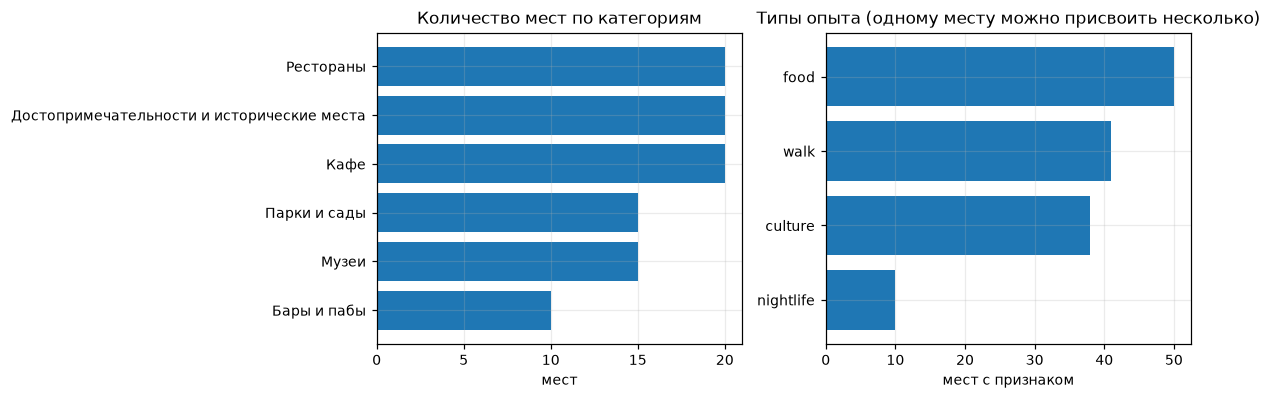

Категории:


,количество
category,
Бары и пабы,10
Музеи,15
Парки и сады,15
Кафе,20
Достопримечательности и исторические места,20
Рестораны,20


In [18]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
cat_counts = dataset["category"].value_counts().sort_values()
axes[0].barh(cat_counts.index, cat_counts.values)
axes[0].set_title("Количество мест по категориям")
axes[0].set_xlabel("мест")
exp_counts = dataset.explode("experience")["experience"].value_counts().sort_values()
axes[1].barh(exp_counts.index, exp_counts.values)
axes[1].set_title("Типы опыта (одному месту можно присвоить несколько)")
axes[1].set_xlabel("мест с признаком")
plt.tight_layout()
plt.show()

print("Категории:")
display(cat_counts.rename("количество").to_frame())

Квоты делают набор сбалансированным по заранее выбранным категориям, но не обязательно по сценариям использования. Например, гастрономических мест несколько категорий, поэтому `food` может встречаться чаще других типов опыта. Это полезно учитывать при тестировании: восемь удачных запросов про еду не означают, что система одинаково хорошо работает для любого сценария.

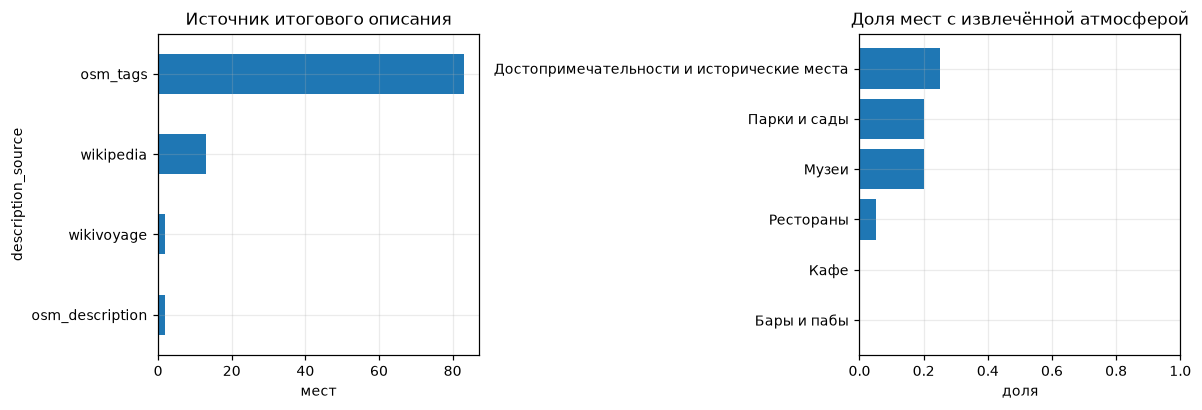

Источники описаний:


,количество
description_source,
osm_tags,83
wikipedia,13
wikivoyage,2
osm_description,2



Покрытие основных полей:


,поле,"заполнено, %"
0,address,100.0
1,description,100.0
2,website,17.0
3,phone,18.0
4,opening_hours,42.0
5,cuisine,12.0
6,wikipedia_url,13.0
7,wikivoyage_url,2.0
8,reviews,0.0


In [19]:
# покрытие описаниями и признаки по категориям
if "description_source" not in dataset:
    dataset["description_source"] = "unknown"
source_counts = dataset["description_source"].fillna("unknown").replace("", "unknown").value_counts()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
source_counts.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Источник итогового описания")
axes[0].set_xlabel("мест")

atm_by_cat = dataset.assign(_has_atm=dataset["atmosphere"].apply(lambda x: bool(x) if isinstance(x, list) else False)).groupby("category")["_has_atm"].mean().sort_values()
axes[1].barh(atm_by_cat.index, atm_by_cat.values)
axes[1].set_xlim(0, 1)
axes[1].set_title("Доля мест с извлечённой атмосферой")
axes[1].set_xlabel("доля")
plt.tight_layout()
plt.show()

print("Источники описаний:")
display(source_counts.rename("количество").to_frame())
print("\nПокрытие основных полей:")
fields = [c for c in ["address", "description", "website", "phone", "opening_hours", "cuisine", "wikipedia_url", "wikivoyage_url", "reviews"] if c in dataset.columns]
field_coverage = pd.DataFrame({"поле": fields, "заполнено, %": [round(dataset[c].fillna("").astype(str).str.strip().ne("").mean()*100, 1) for c in fields]})
display(field_coverage)

Если `description_source` показывает много `osm_tags`, значит поле описания заполнено за счёт короткого фактического шаблона, а не полноценного редакционного текста. Особенно внимательно смотрю на атмосферу: низкое покрытие ограничивает запросы вроде «уютное», «тихое» или «романтичное». Без легального и достаточно содержательного текстового источника это не исправить одними настройками поиска

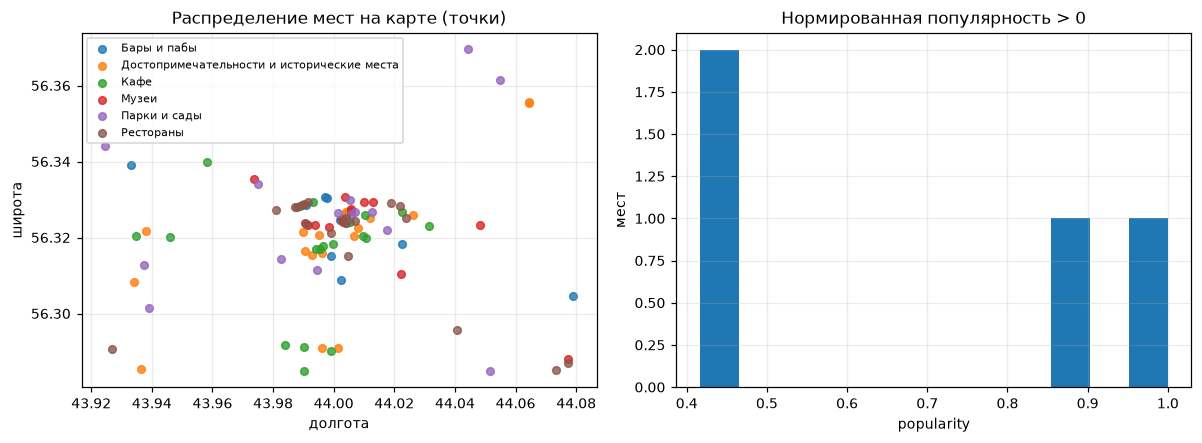

Мест с координатами: 100 из 100
Мест с popularity > 0: 4


In [20]:
# география и недостающие координаты
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
if {"lat", "lon"}.issubset(dataset.columns):
    for category, part in dataset.groupby("category"):
        axes[0].scatter(pd.to_numeric(part["lon"], errors="coerce"), pd.to_numeric(part["lat"], errors="coerce"), s=25, alpha=.8, label=category)
    axes[0].legend(fontsize=7, loc="best")
    axes[0].set_xlabel("долгота"); axes[0].set_ylabel("широта")
    axes[0].set_title("Распределение мест на карте (точки)")
else:
    axes[0].text(.5, .5, "Координаты не найдены", ha="center", va="center")
    axes[0].set_axis_off()

if "popularity" in dataset:
    values = pd.to_numeric(dataset["popularity"], errors="coerce").fillna(0)
    axes[1].hist(values[values > 0], bins=12)
    axes[1].set_title("Нормированная популярность > 0")
    axes[1].set_xlabel("popularity"); axes[1].set_ylabel("мест")
else:
    axes[1].set_axis_off()
plt.tight_layout()
plt.show()

if {"lat", "lon"}.issubset(dataset.columns):
    print("Мест с координатами:", dataset[["lat", "lon"]].notna().all(axis=1).sum(), "из", len(dataset))
print("Мест с popularity > 0:", int((pd.to_numeric(dataset.get("popularity", 0), errors="coerce").fillna(0) > 0).sum()) if isinstance(dataset.get("popularity", 0), pd.Series) else 0)

По географическому графику можно проверить, не слишком ли сильно выборка стянута к центру. Но эти 100 мест не репрезентируют все заведения города: радиус, OSM-разметка и квоты задают смещение заранее. `popularity` тоже не является рейтингом посетителей: в текущем варианте это слабый прокси по числу языковых ссылок Wikipedia, и у большинства кафе такого сигнала, скорее всего, не будет

## Задание 5. Поиск мест под естественный запрос

Здесь проверяю, помогает ли сочетание текста и структурированных признаков лучше ранжировать места. Сравниваю три варианта:

1. **TF-IDF** — простой лексический baseline, хорошо ловящий прямые совпадения слов
2. **LSA** — TF-IDF, сжатый через `TruncatedSVD`
3. **Гибрид** — первые два вместе

Набор тестовых запросов фиксирую, чтобы методы оценивались на одних и тех же примерах. Метрики ниже основаны на тех же автоматически извлечённых признаках, поэтому это проверка согласованности, а не независимая человеческая оценка релевантности

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize as sk_normalize

# для поиска использую название, категорию и все доступные текстовые поля
def searchable_text(row):
    parts = [get_cell(row, c, "") for c in ["name", "category", "description", "editorial_note", "cuisine", "address"]]
    tags_json = get_cell(row, "tags_json", "")
    parts.append(tags_json)
    return normalize_text(" ".join(str(x) for x in parts if x is not None))

corpus = dataset.apply(searchable_text, axis=1).tolist()
if not corpus or len(corpus) < 3:
    raise ValueError("Для сравнения поиска нужно хотя бы три места. Проверь результат заданий 1–3.")

word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=20000, sublinear_tf=True)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1, max_features=30000, sublinear_tf=True)
Xw = word_vec.fit_transform(corpus)
Xc = char_vec.fit_transform(corpus)

n_components = min(32, Xw.shape[0] - 1, Xw.shape[1] - 1)
if n_components >= 2:
    svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
    Xl = sk_normalize(svd.fit_transform(Xw))
else:
    svd = None
    Xl = None

print("Документов:", len(corpus), "| word features:", Xw.shape[1], "| char features:", Xc.shape[1])
print("LSA components:", n_components if svd is not None else "недостаточно данных")

Документов: 100 | word features: 3837 | char features: 20464
LSA components: 32


### 5.1. Разбор интента и ранжирование

Парсер запроса здесь тоже rule-based. Он выделяет категорию, атмосферу, контекст, сценарий, бюджет и время суток. В гибриде категория сильно понижает места из неподходящих категорий, а совпадение признаков помогает, когда пользователь описывает не объект, а ситуацию

In [22]:
CATEGORY_HINTS = [
    (r"\bкафе\b|\bкофейн|\bкофе\b", {"Кафе"}),
    (r"\bресторан|\bужин|\bпоужин", {"Рестораны"}),
    (r"\bпообед|\bобед|\bпоесть|\bперекус", {"Кафе", "Рестораны"}),
    (r"\bбар\b|\bпаб\b", {"Бары и пабы"}),
    (r"\bмузе", {"Музеи"}),
    (r"\bпарк\b|\bсквер", {"Парки и сады"}),
    (r"\bпрогул", {"Парки и сады", "Достопримечательности и исторические места"}),
    (r"\bдостопримечательн|\bкремл|\bисторическ", {"Достопримечательности и исторические места"}),
]
SLOT_HINTS = {"morning": r"\bутр", "day": r"\bдн[её]м|\bобед|\bднём", "evening": r"\bвечер", "night": r"\bноч"}

def parse_intent(query):
    q = normalize_text(query)
    cats = set()
    for pattern, values in CATEGORY_HINTS:
        if re.search(pattern, q):
            cats.update(values)
    atmosphere, _ = extract_labels(q, "atmosphere")
    context, _ = extract_labels(q, "context")
    experience, _ = extract_labels(q, "experience")
    budget = "high" if find_hits(q, HIGH_PAT) else ("low" if find_hits(q, LOW_PAT) else None)
    slots = [slot for slot, pattern in SLOT_HINTS.items() if re.search(pattern, q)]
    return {"cats": cats, "atmosphere": atmosphere, "context": context,
            "experience": experience, "budget": budget, "slots": slots}

def row_feature_score(row, intent):
    expected = []
    actual = []
    for label in intent["atmosphere"]:
        expected.append(label); actual.append(label in row["atmosphere"])
    for label in intent["context"]:
        expected.append(label); actual.append(label in row["context"])
    for label in intent["experience"]:
        expected.append(label); actual.append(label in row["experience"])
    if intent["budget"]:
        expected.append("budget")
        actual.append(row["budget"] in ({"low", "free"} if intent["budget"] == "low" else {intent["budget"]}))
    for slot in intent["slots"]:
        expected.append(slot); actual.append(slot in row["time_slots"])
    return float(np.mean(actual)) if actual else 0.0

def search(query, method="hybrid", k=5):
    qw = word_vec.transform([query])
    if method == "tfidf":
        scores = (Xw @ qw.T).toarray().ravel()
    elif method == "lsa":
        if svd is None:
            scores = (Xw @ qw.T).toarray().ravel()
        else:
            ql = sk_normalize(svd.transform(qw))
            scores = (Xl @ ql.T).ravel()
    elif method == "hybrid":
        qc = char_vec.transform([query])
        sim_w = (Xw @ qw.T).toarray().ravel()
        sim_c = (Xc @ qc.T).toarray().ravel()
        if svd is not None:
            ql = sk_normalize(svd.transform(qw))
            sim_l = (Xl @ ql.T).ravel()
        else:
            sim_l = sim_w
        feature_scores = np.array([row_feature_score(dataset.iloc[i], parse_intent(query)) for i in range(len(dataset))])
        popularity = pd.to_numeric(dataset.get("popularity", pd.Series(0, index=dataset.index)), errors="coerce").fillna(0).to_numpy()
        scores = 0.35 * sim_w + 0.10 * sim_c + 0.10 * sim_l + 0.35 * feature_scores + 0.10 * popularity
        intent = parse_intent(query)
        if intent["cats"]:
            wrong_category = ~dataset["category"].isin(intent["cats"]).to_numpy()
            scores = np.where(wrong_category, scores * 0.25, scores)
    else:
        raise ValueError("method должен быть tfidf, lsa или hybrid")
    return np.argsort(-scores)[:min(k, len(dataset))].tolist(), scores

QUERIES = [
    "кафе, где можно поработать с ноутбуком",
    "романтический ужин на двоих вечером",
    "куда сходить с детьми в выходной",
    "недорого пообедать днём",
    "бар с живой музыкой вечером",
    "музей истории для туриста",
    "тихая прогулка с видом на Волгу",
    "уютное кафе",
]

METHODS = ["tfidf", "lsa", "hybrid"]
def show_results(query, k=3):
    intent = parse_intent(query)
    print(f"\nЗапрос: {query}")
    print("Интент:", {k: sorted(v) if isinstance(v, set) else v for k, v in intent.items()})
    for method in METHODS:
        indices, scores = search(query, method, k)
        results = []
        for idx in indices:
            row = dataset.iloc[idx]
            results.append(f"{row['name']} [{row['category']}] — {scores[idx]:.3f}")
        print(f"{method:7}: " + " | ".join(results))

for query in QUERIES:
    show_results(query, k=3)


Запрос: кафе, где можно поработать с ноутбуком
Интент: {'cats': ['Кафе'], 'atmosphere': [], 'context': ['work'], 'experience': [], 'budget': None, 'slots': []}
tfidf  : 7 гость [Кафе] — 0.130 | Beerлога [Кафе] — 0.130 | Столовая [Кафе] — 0.114
lsa    : 7 гость [Кафе] — 0.884 | Столовая [Кафе] — 0.865 | Alt lib [Кафе] — 0.850
hybrid : #Бургер [Кафе] — 0.403 | 7 гость [Кафе] — 0.140 | Beerлога [Кафе] — 0.133

Запрос: романтический ужин на двоих вечером
Интент: {'cats': ['Рестораны'], 'atmosphere': ['romantic'], 'context': ['date'], 'experience': ['food'], 'budget': None, 'slots': ['evening']}
tfidf  : На дне [Бары и пабы] — 0.184 | 76-мм пушка ЗиС-3 [Достопримечательности и исторические места] — 0.091 | Стрелка [Парки и сады] — 0.087
lsa    : Bar Cuba Leal [Бары и пабы] — 0.477 | На дне [Бары и пабы] — 0.468 | Вок & вафля [Рестораны] — 0.465
hybrid : Вок & вафля [Рестораны] — 0.253 | Escape [Рестораны] — 0.215 | Сиба ину [Рестораны] — 0.188

Запрос: куда сходить с детьми в выходной
Инте

### 5.2. Сравнение на одинаковых запросах

Использую `P@5` - долю подходящих мест среди первых пяти результатов. Поскольку готовой ручной разметки «запрос → релевантное место» у меня нет, релевантность здесь приближённая: она считается по категории и признакам, которые сама же система извлекает. Поэтому результат полезен для сравнения реализаций, но не доказывает, что рекомендации действительно понравятся пользователю

In [23]:
def relevance_grade(row, intent):
    checks = []
    if intent["cats"]:
        checks.append(row["category"] in intent["cats"])
    checks.extend(label in row["atmosphere"] for label in intent["atmosphere"])
    checks.extend(label in row["context"] for label in intent["context"])
    checks.extend(label in row["experience"] for label in intent["experience"])
    if intent["budget"]:
        checks.append(row["budget"] in ({"low", "free"} if intent["budget"] == "low" else {intent["budget"]}))
    checks.extend(slot in row["time_slots"] for slot in intent["slots"])
    if not checks:
        return 1.0
    if all(checks):
        return 1.0
    if any(checks):
        return 0.5
    return 0.0

comparison_rows = []
for query in QUERIES:
    intent = parse_intent(query)
    for method in METHODS:
        top, scores = search(query, method, k=5)
        grades = [relevance_grade(dataset.iloc[i], intent) for i in top]
        category_precision = np.mean([dataset.iloc[i]["category"] in intent["cats"] for i in top]) if intent["cats"] else np.nan
        comparison_rows.append({
            "query": query, "method": method,
            "p5_category": round(float(category_precision), 3) if not pd.isna(category_precision) else np.nan,
            "p5_any_rule": round(float(np.mean([g > 0 for g in grades])), 3),
            "p5_full_rule": round(float(np.mean([g == 1 for g in grades])), 3),
            "top5": "; ".join(str(dataset.iloc[i]["name"]) for i in top),
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison)
print("\nСредние метрики по методам:")
display(comparison.groupby("method")[["p5_category", "p5_any_rule", "p5_full_rule"]].mean().round(3))
comparison.to_csv("search_comparison.csv", index=False, encoding="utf-8-sig")
print("Сохранён файл search_comparison.csv")

,query,method,p5_category,p5_any_rule,p5_full_rule,top5
0,"кафе, где можно поработать с ноутбуком",tfidf,1.0,1.0,0.0,7 гость; Beerлога; Столовая; Black Shisha; Aura-кальянная
1,"кафе, где можно поработать с ноутбуком",lsa,1.0,1.0,0.0,7 гость; Столовая; Alt lib; Beerлога; Black Shisha
2,"кафе, где можно поработать с ноутбуком",hybrid,1.0,1.0,0.2,#Бургер; 7 гость; Beerлога; Столовая; Alt lib
3,романтический ужин на двоих вечером,tfidf,0.2,0.6,0.0,На дне; 76-мм пушка ЗиС-3; Стрелка; Вок & вафля; 57-мм пушка ЗиС-3
4,романтический ужин на двоих вечером,lsa,0.2,0.6,0.0,Bar Cuba Leal; На дне; Вок & вафля; 76-мм пушка ЗиС-3; 57-мм пушка ЗиС-3
5,романтический ужин на двоих вечером,hybrid,1.0,1.0,0.0,Вок & вафля; Escape; Сиба ину; Папаша Билли; Grill House & Домашняя Италия
6,куда сходить с детьми в выходной,tfidf,NaN,0.0,0.0,#Бургер; 5 минут; 7 гость; Aloha & poke vibe; Alt lib
7,куда сходить с детьми в выходной,lsa,NaN,0.0,0.0,#Бургер; 5 минут; 7 гость; Aloha & poke vibe; Alt lib
8,куда сходить с детьми в выходной,hybrid,NaN,1.0,1.0,"Домик Каширина; Дети Кулибина; Детский парк; Центр современного искусства ""Арсенал""; Дворец детс..."
9,недорого пообедать днём,tfidf,1.0,1.0,0.0,#Бургер; 5 минут; 7 гость; Aloha & poke vibe; Alt lib



Средние метрики по методам:


,p5_category,p5_any_rule,p5_full_rule
method,,,
hybrid,1.000,1.000,0.325
lsa,0.771,0.725,0.100
tfidf,0.800,0.750,0.100


Сохранён файл search_comparison.csv


### Что значит результат

Если гибрид выигрывает на запросах с явной категорией, это ожидаемо: он использует категорию как сильный сигнал, тогда как TF-IDF может зацепиться за случайное слово в описании. Если запрос содержит «уютное», «тихое» или «для работы», качество зависит от того, есть ли такие признаки в данных. Отсутствие подходящего места в топе нельзя исправить только перенастройкой весов - иногда в датасете просто нет подтверждающего текста

## Итог по заданиям 1–5

- `places_raw.csv` — выбранные места с исходными тегами OSM;
- `places_enriched.csv` — места после обогащения доступными описаниями и ссылками;
- `places_features.csv` — датасет с семантическими и практическими признаками;
- `search_comparison.csv` — сравнение трёх поисковых методов на фиксированных запросах;
- `poi_feature_schema.csv` — описание схемы признаков.

Отзывы оставляю пустыми: для них нужен источник, который разрешает такое использование данных. Сильнейшее ограничение сейчас - недостаток содержательных описаний для заведений, поэтому атмосфера и контекст извлекаются редко. Гибридный поиск позволяет лучше использовать имеющиеся структурированные признаки, но не заменяет недостающую информацию. Без нее дальнейшие реализации не дадут гарантии, что она правда хорошо или плохо работает, не проверить